In [1]:
import pandas as pd
import numpy as np

import matplotlib as plt
import seaborn as sns
import statsmodels

from geopy.distance import geodesic
from libpysal.weights import KNN
from esda.moran import Moran

In [2]:
df = pd.read_csv("../data/raw/data_land_23-25.csv")
df.head()

,tanggal,stasiun,pm25,pm10,so2,co,o3,no2,max,critical,...,t2m_c,d2m_c,skt_c,sp_hpa,u10,v10,wind_speed,sshf,ssrd,tp_mm
0,2023-01-01,DKI1 (Bunderan HI),55.0,44.0,47.0,10.0,24.0,9.0,55.0,PM25,...,25.556402,22.932364,25.707747,1007.17020,3.359575,0.245406,3.497011,-11828434.0,16794192.0,21.383282
1,2023-01-02,DKI1 (Bunderan HI),43.0,32.0,52.0,9.0,24.0,8.0,52.0,SO2,...,25.909555,22.809381,26.312996,1007.04736,3.690684,0.154770,3.842652,-19416040.0,19450636.0,5.191999
2,2023-01-03,DKI1 (Bunderan HI),35.0,31.0,49.0,9.0,12.0,7.0,49.0,SO2,...,25.244545,22.703054,25.309061,1006.91550,3.759351,1.106680,3.986183,-8033309.5,14011936.0,20.043148
3,2023-01-04,DKI1 (Bunderan HI),47.0,30.0,53.0,11.0,15.0,9.0,53.0,SO2,...,25.186163,22.388178,24.980600,1006.34700,3.171578,0.234373,3.352136,-2020401.0,25899534.0,10.425209
4,2023-01-05,DKI1 (Bunderan HI),50.0,38.0,50.0,13.0,26.0,11.0,50.0,PM25,...,26.122606,22.259958,26.653069,1006.44745,2.284141,0.517420,2.527324,-16885396.0,19027820.0,1.566000


In [27]:
df.columns

Index(['tanggal', 'stasiun', 'pm25', 'pm10', 'so2', 'co', 'o3', 'no2', 'max',
       'critical', 'categori', 'lat', 'lon', 'pm25_lag1', 'month',
       'day_of_week', 'is_weekend', 't2m_c', 'd2m_c', 'skt_c', 'sp_hpa', 'u10',
       'v10', 'wind_speed', 'sshf', 'ssrd', 'tp_mm', 'pm25_missing'],
      dtype='str')

In [3]:
df["tanggal"] = pd.to_datetime(df["tanggal"])

df = df.sort_values(["stasiun", "tanggal"]).reset_index(drop=True)

cat_cols = [
    "stasiun",
    "critical",
    "categori"
]

for col in cat_cols:
    df[col] = df[col].astype("category")

# Missing values Diagnostics

In [4]:
(
    df.groupby("stasiun")["pm25"]
    .apply(lambda x: x.isna().mean() * 100)
    .round(2)
)

stasiun
DKI1 (Bunderan HI)       1.14
DKI2 (Kelapa Gading)     0.63
DKI3 (Jagakarsa)         1.90
DKI4 (Lubang Buaya)      2.03
DKI5 (Kebon Jeruk)      34.94
Name: pm25, dtype: float64

In [5]:
df["pm25_missing"] = df["pm25"].isna()

(
    df.groupby("stasiun")["pm25_missing"]
    .sum()
)

stasiun
DKI1 (Bunderan HI)        9
DKI2 (Kelapa Gading)      5
DKI3 (Jagakarsa)         15
DKI4 (Lubang Buaya)      16
DKI5 (Kebon Jeruk)      276
Name: pm25_missing, dtype: int64

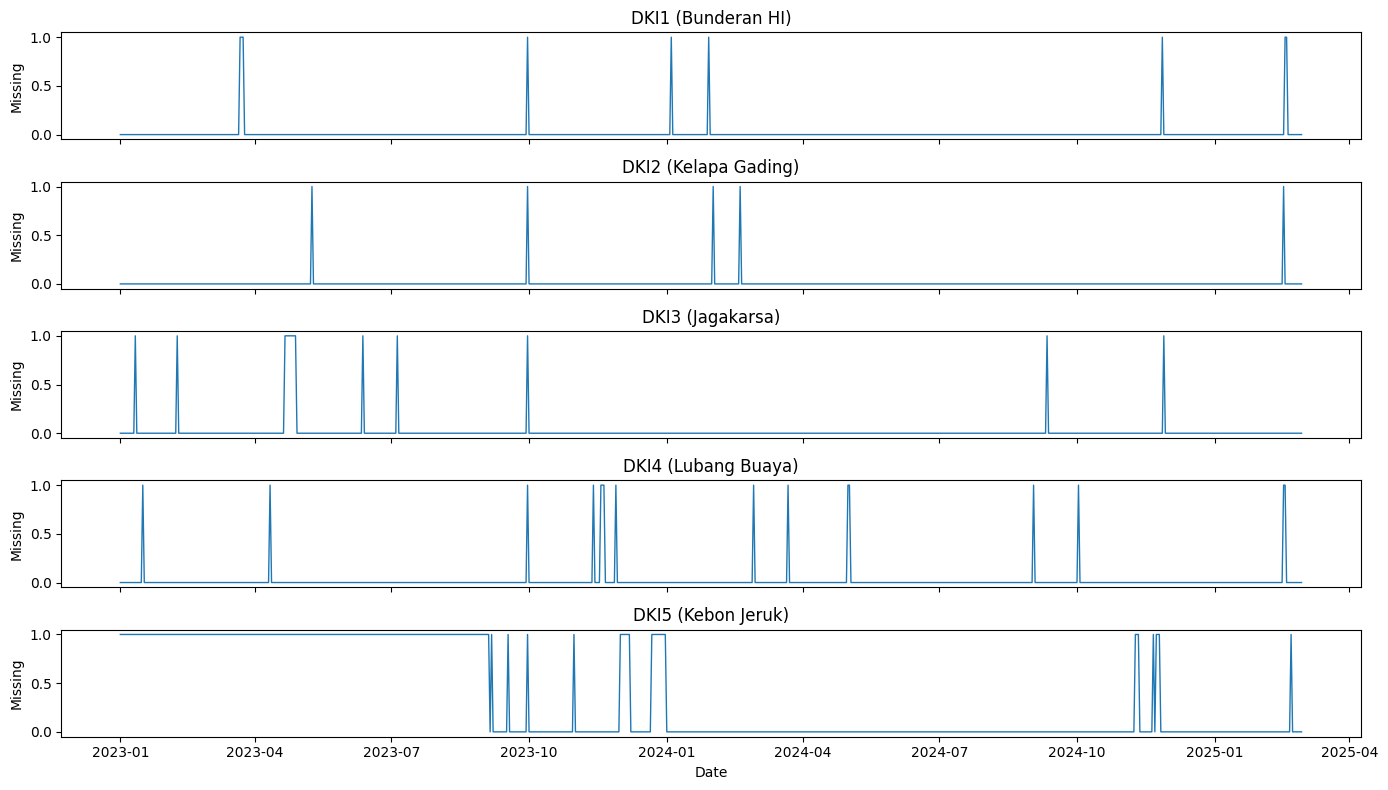

In [6]:
import matplotlib.pyplot as plt

stations = df["stasiun"].unique()

fig, axes = plt.subplots(
    len(stations),
    1,
    figsize=(14, 8),
    sharex=True
)

for ax, station in zip(axes, stations):

    temp = (
        df[df["stasiun"] == station]
        .sort_values("tanggal")
    )

    ax.plot(
        temp["tanggal"],
        temp["pm25"].isna().astype(int),
        linewidth=1
    )

    ax.set_title(station)
    ax.set_ylabel("Missing")

plt.xlabel("Date")

plt.tight_layout()
plt.show()

# Missing Values Diagnostics

- Most stations showed sparse and isolated missing PM2.5 observations.
- DKI5 (Kebon Jeruk) had a large missing gap during early–mid 2023, indicating possible sensor outage or monitoring interruption.
- Meteorological variables and spatial coordinates were fully complete.

- Missing observations may affect:
  - temporal continuity
  - lag features
  - rolling statistics

- INLA-SPDE and latent Gaussian models are relatively tolerant to:
  - irregular observation structures
  - partially missing responses

- This type of missingness is common in:
  - environmental monitoring
  - epidemiology
  - geostatistics

- Missing values do not invalidate the modelling framework, but require careful handling during feature engineering.

# Spatial Diagnostics

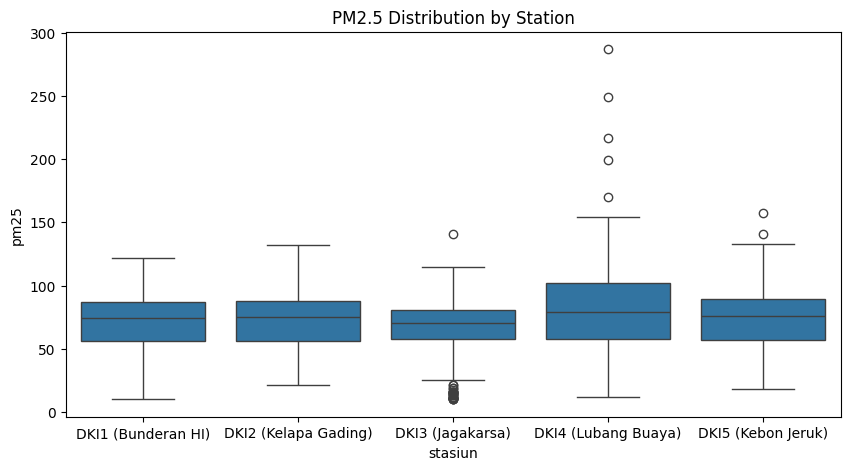

In [7]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x="stasiun",
    y="pm25"
)

plt.title("PM2.5 Distribution by Station")

plt.show()

---
## PM2.5 Distribution by Station

- Most stations had relatively similar PM2.5 distributions.
- DKI4 (Lubang Buaya) showed:
  - higher variability
  - more extreme pollution events
  - heavier upper tail
- Indicates localized pollution heterogeneity across Jakarta.
---

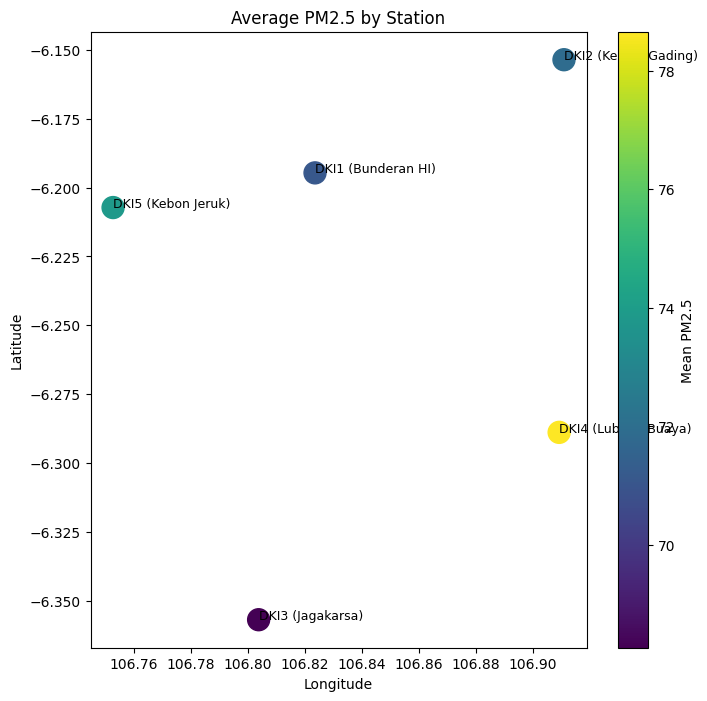

In [8]:
station_mean = (
    df.groupby("stasiun")
    .agg({
        "pm25":"mean",
        "lat":"first",
        "lon":"first"
    })
    .reset_index()
)

plt.figure(figsize=(8,8))

sc = plt.scatter(
    station_mean["lon"],
    station_mean["lat"],
    c=station_mean["pm25"],
    s=250
)

for _, row in station_mean.iterrows():
    plt.text(
        row["lon"],
        row["lat"],
        row["stasiun"],
        fontsize=9
    )

plt.colorbar(sc, label="Mean PM2.5")

plt.title("Average PM2.5 by Station")

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

---
## Average PM2.5 by Station

- Mean PM2.5 ranged approximately:
  - lowest: DKI3 (Jagakarsa) ≈ 68
  - highest: DKI4 (Lubang Buaya) ≈ 79

- Spatial differences were moderate rather than extreme.
- DKI4 also had:
  - highest standard deviation
  - highest maximum PM2.5 value
---

In [9]:
stations = (
    df[["stasiun", "lat", "lon"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

distance_matrix = pd.DataFrame(
    index=stations["stasiun"],
    columns=stations["stasiun"]
)

for i, row1 in stations.iterrows():
    for j, row2 in stations.iterrows():

        dist = geodesic(
            (row1["lat"], row1["lon"]),
            (row2["lat"], row2["lon"])
        ).km

        distance_matrix.iloc[i, j] = round(dist, 2)

print(distance_matrix)

stasiun              DKI1 (Bunderan HI) DKI2 (Kelapa Gading) DKI3 (Jagakarsa)  \
stasiun                                                                         
DKI1 (Bunderan HI)                  0.0                10.69            18.08   
DKI2 (Kelapa Gading)              10.69                  0.0            25.43   
DKI3 (Jagakarsa)                  18.08                25.43              0.0   
DKI4 (Lubang Buaya)               14.09                14.97            13.89   
DKI5 (Kebon Jeruk)                 7.97                 18.5            17.49   

stasiun              DKI4 (Lubang Buaya) DKI5 (Kebon Jeruk)  
stasiun                                                      
DKI1 (Bunderan HI)                 14.09               7.97  
DKI2 (Kelapa Gading)               14.97               18.5  
DKI3 (Jagakarsa)                   13.89              17.49  
DKI4 (Lubang Buaya)                  0.0              19.54  
DKI5 (Kebon Jeruk)                 19.54                0.0 

---

## Distance Matrix

- Inter-station distances ranged approximately:
  - minimum ≈ 8 km
  - maximum ≈ 25 km

- Stations provide moderate spatial coverage across Jakarta.
- Spatial separation is sufficient for exploratory spatial modelling.
---

In [10]:
spatial_summary = (
    df.groupby("stasiun")["pm25"]
    .agg(["mean", "std", "max"])
)

print(spatial_summary)

                           mean        std    max
stasiun                                          
DKI1 (Bunderan HI)    71.093470  20.117736  122.0
DKI2 (Kelapa Gading)  71.908280  21.055726  132.0
DKI3 (Jagakarsa)      68.261935  19.767898  141.0
DKI4 (Lubang Buaya)   78.657623  32.207089  287.0
DKI5 (Kebon Jeruk)    73.857977  24.213098  157.0


---
## Spatial Summary

- Temporal variability appeared stronger than spatial variability.
- PM2.5 dynamics seem dominated by:
  - temporal persistence
  - shared meteorological conditions

- Spatial effects appear more localized rather than smoothly distributed.
---

In [11]:
station_mean = (
    df.groupby("stasiun")
    .agg({
        "pm25": "mean",
        "lat": "first",
        "lon": "first"
    })
    .reset_index()
)

station_mean

,stasiun,pm25,lat,lon
0,DKI1 (Bunderan HI),71.093470,-6.194660,106.8235
1,DKI2 (Kelapa Gading),71.908280,-6.153570,106.9109
2,DKI3 (Jagakarsa),68.261935,-6.356930,106.8037
3,DKI4 (Lubang Buaya),78.657623,-6.288890,106.9092
4,DKI5 (Kebon Jeruk),73.857977,-6.207255,106.7526


In [12]:
coords = list(
    zip(
        station_mean["lon"],
        station_mean["lat"]
    )
)

w = KNN.from_array(coords, k=2)

w.transform = "R"

y = station_mean["pm25"].values

moran = Moran(y, w)

In [13]:
print(f"Moran's I : {moran.I:.4f}")
print(f"p-value   : {moran.p_sim:.4f}")

Moran's I : -0.6581
p-value   : 0.0590


---
## Moran’s I

- Moran’s I = -0.6581
- p-value = 0.068

- Indicates weak negative spatial autocorrelation (spatial dispersion).
- Nearby stations did not necessarily exhibit similar PM2.5 concentrations.

- Possible causes:
  - localized urban pollution sources
  - heterogeneous land use
  - microclimate differences
  - sparse monitoring network

- Interpretation should be cautious because:
  - only 5 stations were available
  - Moran’s I becomes unstable with small sample size

- Weak Moran’s I does not invalidate INLA-SPDE because Bayesian spatial models can still capture:
  - latent localized effects
  - structured residual variation
  - spatial uncertainty
---

# Temporal Diagnostics

In [14]:
daily_pm25 = (
    df.groupby("tanggal")["pm25"]
    .mean()
    .reset_index()
)

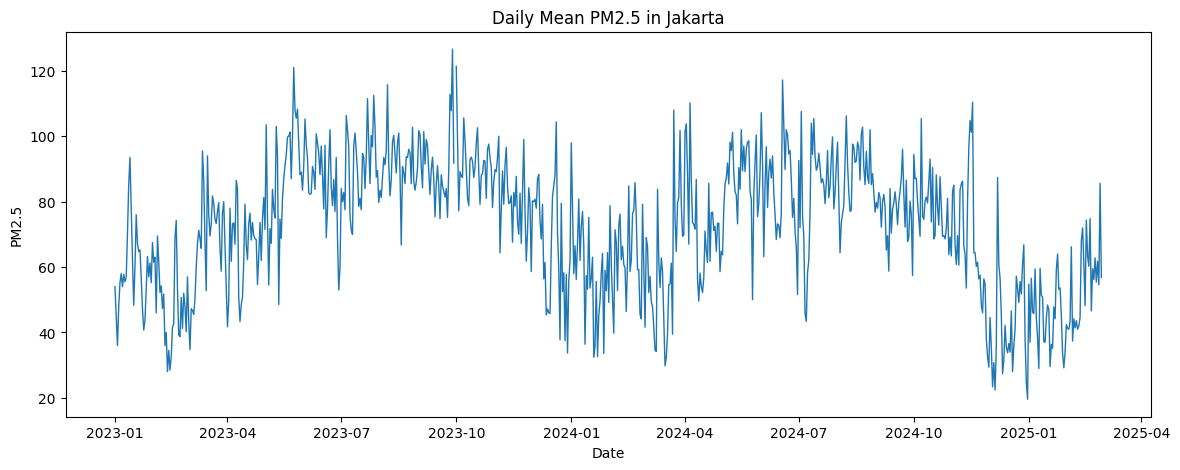

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

plt.plot(
    daily_pm25["tanggal"],
    daily_pm25["pm25"],
    linewidth=1
)

plt.title("Daily Mean PM2.5 in Jakarta")
plt.xlabel("Date")
plt.ylabel("PM2.5")

plt.show()

---
## Nonstationarity

- PM2.5 time series appeared nonstationary in:
  - mean
  - variance

- Pollution levels and volatility changed over time.
- Indicates strong temporal structure.

---

In [16]:
df["month"] = df["tanggal"].dt.month

monthly_pm25 = (
    df.groupby("month")["pm25"]
    .mean()
    .reset_index()
)

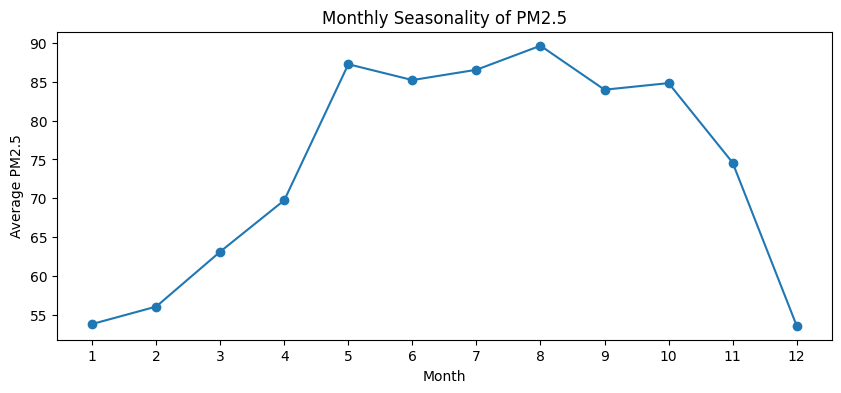

In [17]:
plt.figure(figsize=(10,4))

plt.plot(
    monthly_pm25["month"],
    monthly_pm25["pm25"],
    marker="o"
)

plt.xticks(range(1,13))

plt.title("Monthly Seasonality of PM2.5")
plt.xlabel("Month")
plt.ylabel("Average PM2.5")

plt.show()

---
## Seasonality

- Strong seasonal pattern observed.
- PM2.5 generally:
  - increased from March
  - remained high during dry season (Jun–Sep)
  - peaked around Aug–Sep
  - decreased during rainy season (Nov–Feb)

- Likely caused by:
  - reduced rainfall scavenging
  - pollutant accumulation during dry season

---

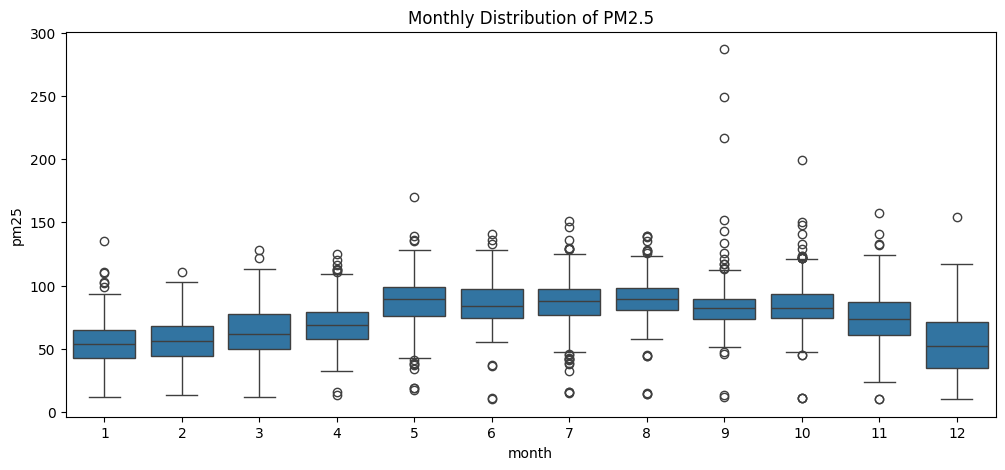

In [18]:
plt.figure(figsize=(12,5))

sns.boxplot(
    data=df,
    x="month",
    y="pm25"
)

plt.title("Monthly Distribution of PM2.5")

plt.show()

---
## Monthly Distribution

- Monthly boxplots confirmed seasonal variation.
- Extreme pollution outliers observed, especially around September.

- Possible causes:
  - haze events
  - biomass burning
  - atmospheric stagnation

- Outliers are environmentally meaningful and should not automatically be removed.

---

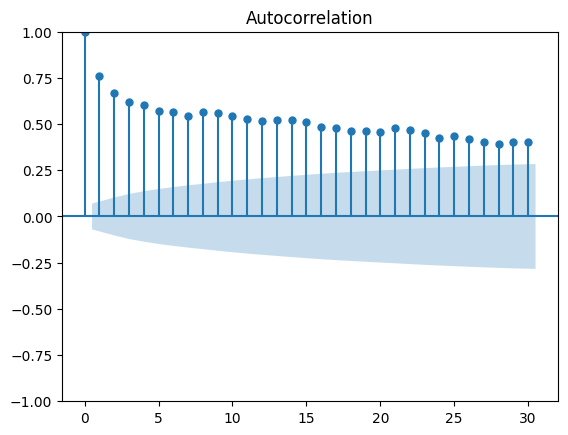

In [19]:
from statsmodels.graphics.tsaplots import plot_acf

series = (
    df.groupby("tanggal")["pm25"]
    .mean()
)

plot_acf(
    series.dropna(),
    lags=30
)

plt.show()

---
## Autocorrelation Function (ACF)

- Strong positive autocorrelation observed.
- Lag-1 autocorrelation was particularly high.
- Autocorrelation decayed slowly across multiple lags.

- Indicates:
  - strong temporal persistence
  - long-range temporal dependence

- Supports:
  - lag features
  - autoregressive structures
  - spatio-temporal modelling
---

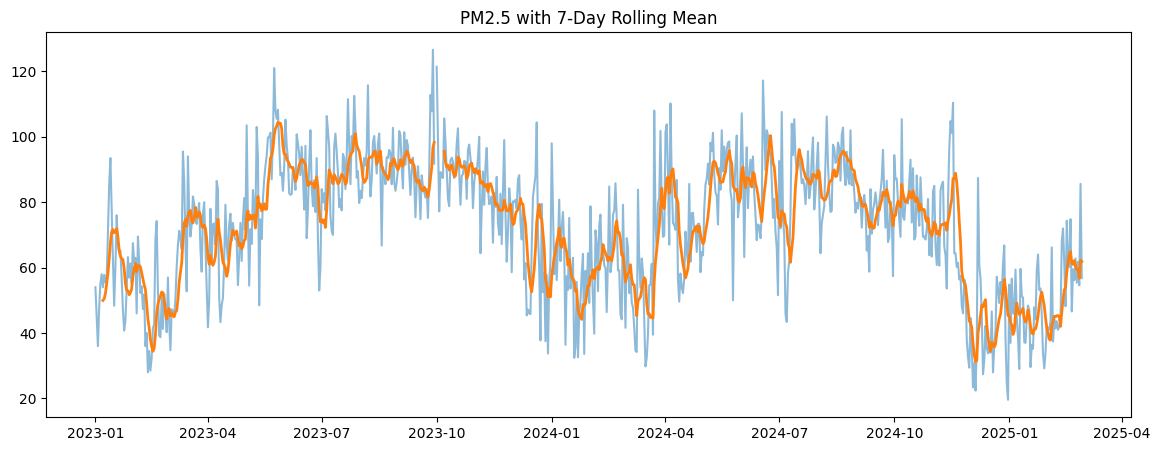

In [20]:
rolling_7 = (
    series.rolling(7)
    .mean()
)

plt.figure(figsize=(14,5))

plt.plot(series, alpha=0.5)
plt.plot(rolling_7, linewidth=2)

plt.title("PM2.5 with 7-Day Rolling Mean")

plt.show()


---

## Rolling Mean

- 7-day rolling mean showed smoother long-term pollution regimes.
- Persistent elevated pollution periods were clearly visible.
- Confirms sustained pollution accumulation and temporal persistence.

---

# Meteorogical Diagnostics

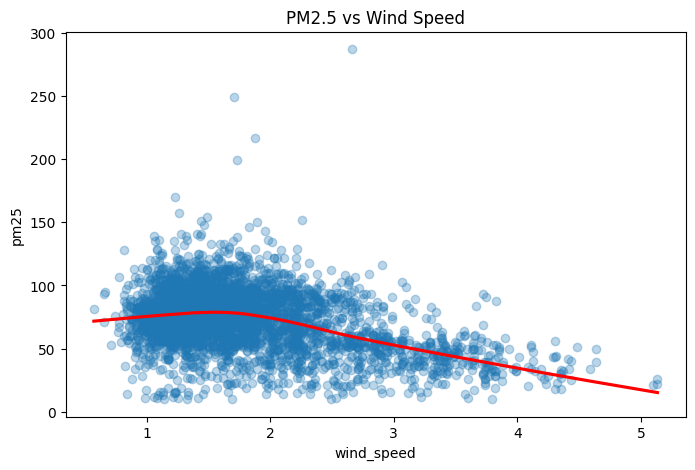

In [21]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df,
    x="wind_speed",
    y="pm25",
    lowess=True,
    scatter_kws={"alpha":0.3},
    line_kws={"color":"red"}
)

plt.title("PM2.5 vs Wind Speed")

plt.show()

---
## PM2.5 vs Wind Speed

- Clear negative relationship observed between wind speed and PM2.5.
- PM2.5 concentrations generally decreased as wind speed increased.

- Suggests:
  - stronger atmospheric dispersion
  - reduced pollutant accumulation under higher wind conditions

- Relationship appeared nonlinear, especially after approximately 2 m/s.
- Supports the use of nonlinear machine learning approaches such as Gradient Boosting.

---

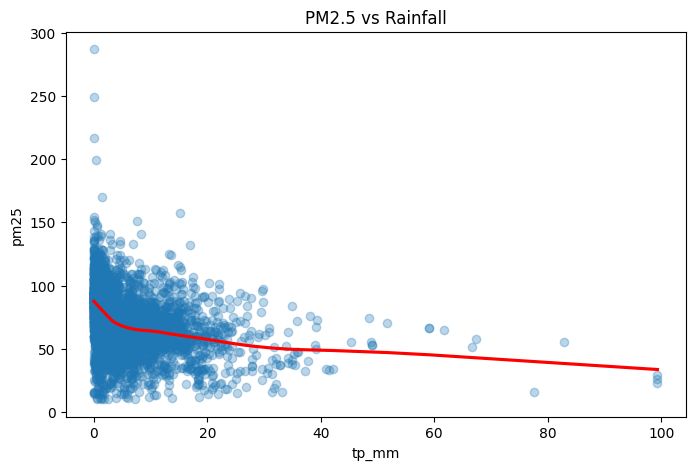

In [22]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df,
    x="tp_mm",
    y="pm25",
    lowess=True,
    scatter_kws={"alpha":0.3},
    line_kws={"color":"red"}
)

plt.title("PM2.5 vs Rainfall")

plt.show()

---
## PM2.5 vs Rainfall

- PM2.5 concentrations generally decreased as rainfall increased.
- Strong reduction observed at lower rainfall levels.

- Indicates:
  - wet deposition
  - aerosol scavenging effects

- Relationship appeared nonlinear with diminishing effects at higher rainfall amounts.

---